# Desafio RMI — análise exploratória

Este notebook mostra os achados nos dados que orientaram as decisões do projeto dbt e
reproduz os itens 4, 6 e 7 da análise do README. Ele lê os Parquets localmente com DuckDB,
sem gastar cota do BigQuery, e reaplica as mesmas regras da staging: ids em texto,
deduplicação e correção do ×100.

**Como rodar**, da raiz do repositório:

```bash
mkdir -p data && gcloud storage cp "gs://case_vagas/rmi/*" data/
uv run jupyter lab notebooks/eda.ipynb
```

No Jupyter, use **Kernel → Restart Kernel and Run All Cells**. Para executar sem abrir o
Jupyter: `uv run jupyter nbconvert --to notebook --execute --inplace notebooks/eda.ipynb`.

Os dados são anonimizados e aleatorizados: os números ilustram o método e não descrevem a
rede real.

In [2]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter

DADOS = Path(os.environ.get("RMI_DATA_DIR", "../data"))
con = duckdb.connect()
for tabela in ["aluno", "escola", "turma", "frequencia", "avaliacao"]:
    con.execute(f"create view raw_{tabela} as select * from read_parquet('{DADOS / tabela}')")


def q(sql):
    """Roda uma consulta no DuckDB e devolve um DataFrame."""
    return con.execute(sql).df()


def br(valor, casas=1):
    """Formata um número no padrão brasileiro: 1.234,5."""
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def eixo_br(eixo, casas=0):
    """Aplica o padrão brasileiro aos rótulos de um eixo do matplotlib."""
    eixo.set_major_formatter(FuncFormatter(lambda valor, _: br(valor, casas)))


pd.set_option("display.float_format", lambda valor: br(valor, 2))

# Estilo dos gráficos: uma série só, em azul; referências em cinza; grade discreta.
AZUL, CINZA, TEXTO, TEXTO_2, FUNDO = "#2a78d6", "#8a8984", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": TEXTO_2, "axes.titlecolor": TEXTO,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e3",
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10,
})

## 1. Volumetria e tipos

O schema fornecido com o desafio diz que o id do aluno é STRING e o bimestre é INT64. Nos
Parquets, o id do aluno chega como BLOB (17 bytes) e o bimestre como texto. As datas da
frequência também são texto, como o schema avisa.

**Decisão:** na staging, todo id vira texto (`to_hex` no id do aluno), o bimestre vira
inteiro e as datas viram DATE.

In [3]:
q("""
select 'aluno' as tabela, count(*) as linhas from raw_aluno union all
select 'escola', count(*) from raw_escola union all
select 'turma', count(*) from raw_turma union all
select 'frequencia', count(*) from raw_frequencia union all
select 'avaliacao', count(*) from raw_avaliacao
""")

,tabela,linhas
0,aluno,97044
1,escola,1558
2,turma,97044
3,frequencia,2727684
4,avaliacao,221687


In [4]:
q("""
select table_name as tabela, column_name as coluna, data_type as tipo
from information_schema.columns
where table_name like 'raw_%'
    and column_name in ('id_aluno', 'id_turma', 'id_escola', 'bimestre', 'data_inicio', 'data_fim')
order by 1, 2
""")

,tabela,coluna,tipo
0,raw_aluno,id_aluno,BLOB
1,raw_aluno,id_turma,BIGINT
2,raw_avaliacao,bimestre,VARCHAR
3,raw_avaliacao,id_aluno,BLOB
4,raw_avaliacao,id_turma,BIGINT
5,raw_escola,id_escola,BIGINT
6,raw_frequencia,data_fim,VARCHAR
7,raw_frequencia,data_inicio,VARCHAR
8,raw_frequencia,id_aluno,BLOB
9,raw_frequencia,id_escola,BIGINT


## 2. Chaves repetidas

A frequência repete a chave (aluno, turma, disciplina, início do período) e a avaliação
repete (aluno, turma, bimestre). Parte são linhas idênticas; parte traz valores diferentes.

**Decisão:** deduplicar na staging. Na frequência fica a linha de menor frequência, a de mais
faltas, para não subestimar o absenteísmo. Na avaliação fica a linha com frequência
preenchida e, entre elas, a de menor frequência; empate, a de menores notas.

In [5]:
q("""
with f as (
    select count(*) as n, count(distinct frequencia) as valores
    from raw_frequencia group by id_aluno, id_turma, disciplina, data_inicio having count(*) > 1
),
a as (
    select count(*) as n, count(distinct coalesce(frequencia, -1)) as valores
    from raw_avaliacao group by id_aluno, id_turma, bimestre having count(*) > 1
)
select 'frequencia' as tabela, count(*) as chaves_repetidas,
       (sum(n) - count(*))::bigint as linhas_removidas,
       count(*) filter (where valores > 1) as com_frequencias_diferentes
from f
union all
select 'avaliacao', count(*), (sum(n) - count(*))::bigint, count(*) filter (where valores > 1) from a
""")

,tabela,chaves_repetidas,linhas_removidas,com_frequencias_diferentes
0,frequencia,2556,2576,1093
1,avaliacao,34,34,29


In [6]:
# As mesmas regras da staging, reaplicadas localmente.
con.execute("""
create table frequencia as
select * exclude (ordem) from (
    select cast(id_escola as varchar) as id_escola, lower(hex(id_aluno)) as id_aluno_frequencia,
           cast(id_turma as varchar) as id_turma, disciplina, cast(data_inicio as date) as data_inicio,
           cast(data_fim as date) as data_fim, frequencia as frequencia_bruta,
           row_number() over (partition by id_aluno, id_turma, disciplina, data_inicio
                              order by frequencia) as ordem
    from raw_frequencia
)
where ordem = 1
""")
con.execute("""
create table avaliacao as
select * exclude (ordem) from (
    select lower(hex(id_aluno)) as id_aluno, cast(id_turma as varchar) as id_turma,
           cast(bimestre as integer) as bimestre, frequencia as frequencia_bimestre,
           disciplina_1 as nota_portugues, disciplina_2 as nota_ciencias, disciplina_4 as nota_matematica,
           row_number() over (partition by id_aluno, id_turma, bimestre
                              order by frequencia is null, frequencia nulls first, disciplina_1 nulls first,
                                       disciplina_2 nulls first, disciplina_4 nulls first) as ordem
    from raw_avaliacao
)
where ordem = 1
""")
con.execute("""
create table aluno as
select lower(hex(id_aluno)) as id_aluno, cast(id_turma as varchar) as id_turma, faixa_etaria,
       cast(bairro as varchar) as id_bairro_residencia
from raw_aluno
""")
con.execute("create table matricula as select lower(hex(id_aluno)) as id_aluno, cast(id_turma as varchar) as id_turma from raw_turma")
con.execute("create table escola as select cast(id_escola as varchar) as id_escola, cast(bairro as varchar) as id_bairro_escola from raw_escola")
q("select (select count(*) from frequencia) as frequencia, (select count(*) from avaliacao) as avaliacao")

,frequencia,avaliacao
0,2725108,221653


## 3. A frequência foi gravada sem o ×100

O schema fornecido documenta a fórmula `100 - (faltas_disciplina / dias_letivos)`: falta o
×100. Por isso todos os valores ficam perto de 100 e nenhum aluno aparece abaixo de 75%.
Como `faltas/dias = 100 - frequencia`, a frequência certa sai da própria coluna:
`100 - 100 × (100 - frequencia)`. Um registro gravado como 99,94 (1 falta em 17 dias) é,
na verdade, 94,12%.

**Decisão:** a intermediate aplica a correção. Registros com mais faltas que dias, que dariam
frequência negativa, ficam em 0 e são contados à parte.

In [7]:
con.execute("""
create table frequencia_corrigida as
select *, 100 - 100 * (100 - frequencia_bruta) as frequencia_calculada,
       greatest(100 - 100 * (100 - frequencia_bruta), 0) as frequencia_pct
from frequencia
""")
q("""
select min(frequencia_bruta) as minimo_gravado, max(frequencia_bruta) as maximo_gravado,
       count(*) filter (where frequencia_bruta < 75) as gravados_abaixo_de_75,
       count(*) filter (where frequencia_calculada < 0) as registros_com_mais_faltas_que_dias,
       100 * count(*) filter (where frequencia_calculada < 0) / count(*) as pct_registros_limitados
from frequencia_corrigida
""")

,minimo_gravado,maximo_gravado,gravados_abaixo_de_75,registros_com_mais_faltas_que_dias,pct_registros_limitados
0,"97,33","100,00",0,1857,"0,07"


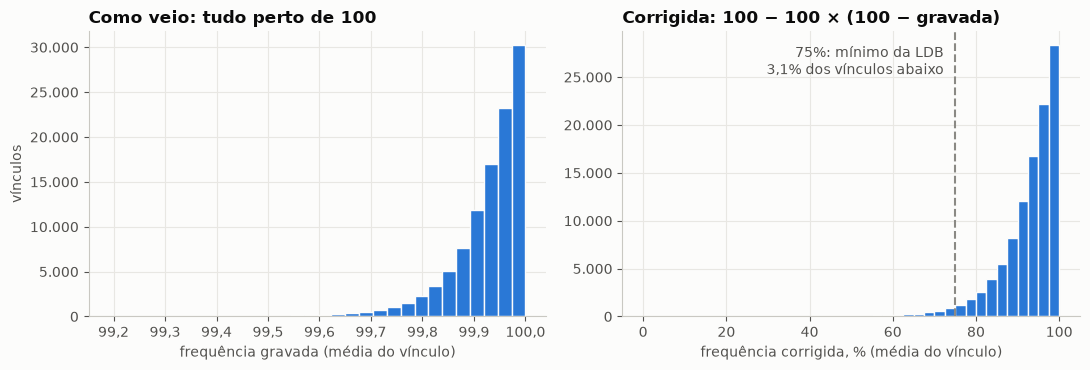

In [8]:
vinculos = q("""
select id_escola, id_turma, id_aluno_frequencia,
       avg(frequencia_bruta) as frequencia_gravada, avg(frequencia_pct) as frequencia_corrigida
from frequencia_corrigida
group by all
""")

fig, (esq, dir_) = plt.subplots(1, 2, figsize=(11, 3.8))
esq.hist(vinculos["frequencia_gravada"], bins=30, color=AZUL, edgecolor=FUNDO, linewidth=1)
esq.set_title("Como veio: tudo perto de 100")
esq.set_xlabel("frequência gravada (média do vínculo)")
esq.set_ylabel("vínculos")
eixo_br(esq.xaxis, 1)
dir_.hist(vinculos["frequencia_corrigida"], bins=40, range=(0, 100), color=AZUL, edgecolor=FUNDO, linewidth=1)
dir_.axvline(75, color=CINZA, linestyle="--", linewidth=1.5)
abaixo = (vinculos["frequencia_corrigida"] < 75).mean() * 100
dir_.annotate(f"75%: mínimo da LDB\n{br(abaixo)}% dos vínculos abaixo", xy=(75, dir_.get_ylim()[1] * 0.85),
              xytext=(-8, 0), textcoords="offset points", ha="right", color=TEXTO_2)
dir_.set_title("Corrigida: 100 − 100 × (100 − gravada)")
dir_.set_xlabel("frequência corrigida, % (média do vínculo)")
for ax in (esq, dir_):
    eixo_br(ax.yaxis)
fig.tight_layout()
plt.show()

## 4. O id de aluno da frequência não identifica o mesmo aluno do cadastro

O schema fornecido diz que esse id foi "mapeado para garantir consistência com a tabela
stg_aluno", e todo id de aluno da frequência existe mesmo no cadastro: um teste de chave
estrangeira passa. Mas quatro testes mostram que não se trata do mesmo aluno:

- quase nenhum par (aluno, turma) da frequência existe na matrícula;
- as turmas do cadastro são homogêneas em idade, mas as da frequência, olhando a idade
  pelo id, ficam tão misturadas quanto um sorteio;
- a escola do aluno pelo cadastro coincide com a da frequência só por acaso;
- aluno a aluno, a frequência corrigida não acompanha a da avaliação; por turma, acompanha.

Dentro da própria frequência, o id é consistente: as faltas do mesmo id em português e em
matemática andam juntas, bem mais que as de dois alunos da mesma turma.

**Decisão:** a frequência nunca se liga ao cadastro, à matrícula ou à avaliação pelo aluno;
só por turma e escola. O teste singular `assert_id_aluno_frequencia_nao_e_o_do_cadastro`
guarda essa premissa.

In [9]:
q("""
with pares as (select distinct id_aluno_frequencia as id_aluno, id_turma from frequencia)
select count(*) as pares, count(matricula.id_aluno) as existem_na_matricula,
       100 * count(matricula.id_aluno) / count(*) as pct
from pares left join matricula using (id_aluno, id_turma)
""")

,pares,existem_na_matricula,pct
0,105934,11,"0,01"


In [10]:
q("""
with via_cadastro as (select id_turma, faixa_etaria from aluno),
via_frequencia as (
    select distinct frequencia.id_turma, frequencia.id_aluno_frequencia, aluno.faixa_etaria
    from frequencia join aluno on aluno.id_aluno = frequencia.id_aluno_frequencia
),
sorteio as (
    select x.id_turma, y.faixa_etaria
    from (select id_turma, row_number() over (order by hash(id_aluno)) as n from aluno) x
    join (select faixa_etaria, row_number() over (order by hash(id_aluno || 'sorteio')) as n from aluno) y using (n)
),
todas as (
    select 'turmas do cadastro' as versao, id_turma, faixa_etaria from via_cadastro
    union all select 'turmas da frequência, idade pelo id', id_turma, faixa_etaria from via_frequencia
    union all select 'controle: idades sorteadas', id_turma, faixa_etaria from sorteio
),
contagem as (select versao, id_turma, faixa_etaria, count(*) as n from todas group by all),
turmas as (select versao, id_turma, sum(n) as total, max(n) as moda from contagem group by all having sum(n) >= 5)
select versao, count(*) as turmas, 100 * avg(moda / total) as pct_na_faixa_mais_comum
from turmas group by versao order by pct_na_faixa_mais_comum desc
""")

,versao,turmas,pct_na_faixa_mais_comum
0,turmas do cadastro,3608,"92,64"
1,controle: idades sorteadas,3608,"53,83"
2,"turmas da frequência, idade pelo id",5516,"51,78"


In [11]:
q("""
with vinculos as (select distinct id_aluno_frequencia, id_turma, id_escola from frequencia),
turma_escola as (select distinct id_turma, id_escola from frequencia),
comparacao as (
    select vinculos.id_escola as escola_na_frequencia, turma_escola.id_escola as escola_pelo_cadastro
    from vinculos
    join aluno on aluno.id_aluno = vinculos.id_aluno_frequencia
    join turma_escola on turma_escola.id_turma = aluno.id_turma
),
acaso as (select sum(p * p) as p from (select count(*) / sum(count(*)) over () as p from vinculos group by id_escola))
select count(*) as vinculos_comparados,
       100 * avg((escola_na_frequencia = escola_pelo_cadastro)::int) as pct_mesma_escola,
       100 * any_value(acaso.p) as pct_esperado_ao_acaso
from comparacao, acaso
""")

,vinculos_comparados,pct_mesma_escola,pct_esperado_ao_acaso
0,59937,"0,30","0,30"


In [12]:
q("""
with freq_aluno as (
    select id_aluno_frequencia as id_aluno, avg(frequencia_pct) as corrigida from frequencia_corrigida group by 1
),
aval_aluno as (
    select id_aluno, avg(frequencia_bimestre) as oficial from avaliacao where bimestre <= 2 group by 1
),
freq_turma as (select id_turma, avg(frequencia_pct) as corrigida from frequencia_corrigida group by 1),
aval_turma as (
    select id_turma, avg(oficial) as oficial
    from (select id_aluno, id_turma, avg(frequencia_bimestre) as oficial
          from avaliacao where bimestre <= 2 and frequencia_bimestre is not null group by all)
    group by id_turma having count(*) >= 5
)
select 'aluno a aluno' as nivel, count(*) as pares, corr(corrigida, oficial) as correlacao
from freq_aluno join aval_aluno using (id_aluno)
union all
select 'por turma', count(*), corr(corrigida, oficial) from freq_turma join aval_turma using (id_turma)
""")

,nivel,pares,correlacao
0,aluno a aluno,68808,"0,00"
1,por turma,1294,"0,69"


In [13]:
# Frequência de cada vínculo no ano, em português e em matemática. O controle compara o
# português de um aluno com a matemática de outro aluno da mesma turma, sorteado.
q("""
with por_disciplina as (
    select id_aluno_frequencia, id_turma,
           avg(frequencia_pct) filter (where disciplina = 'disciplina_1') as portugues,
           avg(frequencia_pct) filter (where disciplina = 'disciplina_4') as matematica
    from frequencia_corrigida group by all
),
outro_aluno as (
    select portugues,
           lead(matematica) over (partition by id_turma order by hash(id_aluno_frequencia)) as matematica_de_outro
    from por_disciplina
)
select (select corr(portugues, matematica) from por_disciplina) as mesmo_id,
       (select corr(portugues, matematica_de_outro) from outro_aluno) as outro_aluno_da_mesma_turma
""")

,mesmo_id,outro_aluno_da_mesma_turma
0,"0,53","0,11"


## 5. Quem a frequência cobre e onde está a escola

Pela faixa etária do cadastro (calculada na data da extração, não no ano letivo), os
alunos das turmas da frequência têm quase todos de 11 a 17 anos, e nenhum tem de 0 a 10.
A escola de uma turma só aparece na frequência: nenhuma outra tabela traz turma e escola
juntas.

**Decisão:** `int_educacao__turma` reúne as turmas das três fontes e marca as que ficam sem
escola, em vez de descartá-las. O mart por escola cobre só as escolas da frequência.

In [14]:
q("""
with turmas_frequencia as (select distinct id_turma from frequencia),
contagem as (
    select faixa_etaria, count(*) as no_cadastro,
           count(*) filter (where id_turma in (select id_turma from turmas_frequencia)) as nas_turmas_da_frequencia
    from aluno group by faixa_etaria
)
select faixa_etaria,
       100 * nas_turmas_da_frequencia / sum(nas_turmas_da_frequencia) over () as pct_nas_turmas_da_frequencia,
       100 * no_cadastro / sum(no_cadastro) over () as pct_no_cadastro
from contagem
order by cast(regexp_extract(faixa_etaria, '^[0-9]+') as integer)
""")

,faixa_etaria,pct_nas_turmas_da_frequencia,pct_no_cadastro
0,0-5,"0,00","8,90"
1,6-10,"0,00","15,48"
2,11-14,"17,01","13,34"
3,15-17,"82,51","51,50"
4,18+,"0,48","10,77"


In [15]:
q("""
with turmas as (
    select id_turma, bool_or(f) as na_frequencia from (
        select distinct id_turma, true as f from frequencia
        union all select distinct id_turma, false from matricula
        union all select distinct id_turma, false from avaliacao
    ) group by id_turma
)
select count(*) as turmas, count(*) filter (where na_frequencia) as com_escola,
       count(*) filter (where not na_frequencia) as sem_escola,
       (select count(distinct id_escola) from frequencia) as escolas_na_frequencia,
       (select count(*) from escola) as escolas_no_cadastro
from turmas
""")

,turmas,com_escola,sem_escola,escolas_na_frequencia,escolas_no_cadastro
0,18060,5516,12544,521,1558


## 6. Bairros

O bairro chega como hash, nos dois cadastros. Os hashes de residência (aluno) e de escola
não têm nenhum valor em comum, e nenhum dos dois se liga à tabela pública de bairros.

**Decisão:** usar o bairro da escola como unidade territorial anônima, sem tentar descobrir
qual bairro é cada hash.

In [16]:
q("""
select (select count(distinct id_bairro_residencia) from aluno) as hashes_de_residencia,
       (select count(distinct id_bairro_escola) from escola) as hashes_de_escola,
       (select count(*) from (select id_bairro_residencia from aluno intersect select id_bairro_escola from escola)) as em_comum
""")

,hashes_de_residencia,hashes_de_escola,em_comum
0,1069,169,0


## 7. Análise: as escolas com maior absenteísmo crônico

A unidade do mart é o aluno na escola: as turmas do mesmo aluno dentro da escola se juntam.
A taxa de cada escola vem com o intervalo de confiança de Wilson (95%), e o ranking só
considera escolas com 30 alunos ou mais, ordenadas pelo limite inferior do intervalo.

In [17]:
alunos_na_escola = q("""
select frequencia_corrigida.id_escola, escola.id_bairro_escola, id_aluno_frequencia,
       avg(frequencia_pct) as frequencia
from frequencia_corrigida join escola using (id_escola)
group by all
""")
alunos_na_escola["abaixo_de_75"] = alunos_na_escola["frequencia"] < 75

escolas = alunos_na_escola.groupby("id_escola").agg(
    alunos=("abaixo_de_75", "size"), abaixo_de_75=("abaixo_de_75", "sum")
).reset_index()
z = 1.96
p, n = escolas["abaixo_de_75"] / escolas["alunos"], escolas["alunos"]
centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
margem = z * ((p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5) / (1 + z**2 / n)
escolas["taxa"] = 100 * p
escolas["ic_inferior"] = (100 * (centro - margem)).clip(lower=0)
escolas["ic_superior"] = (100 * (centro + margem)).clip(upper=100)
taxa_rede = 100 * escolas["abaixo_de_75"].sum() / escolas["alunos"].sum()
suficientes = escolas[escolas["alunos"] >= 30].sort_values("ic_inferior", ascending=False)
print(f"Taxa da rede: {br(taxa_rede)}% ({br(escolas['abaixo_de_75'].sum(), 0)} "
      f"de {br(escolas['alunos'].sum(), 0)} alunos)")
print(f"Escolas com 30 alunos ou mais: {len(suficientes)}; acima da rede com 95% de confiança: "
      f"{(suficientes['ic_inferior'] > taxa_rede).sum()}")

Taxa da rede: 3,1% (3.119 de 100.640 alunos)
Escolas com 30 alunos ou mais: 475; acima da rede com 95% de confiança: 89


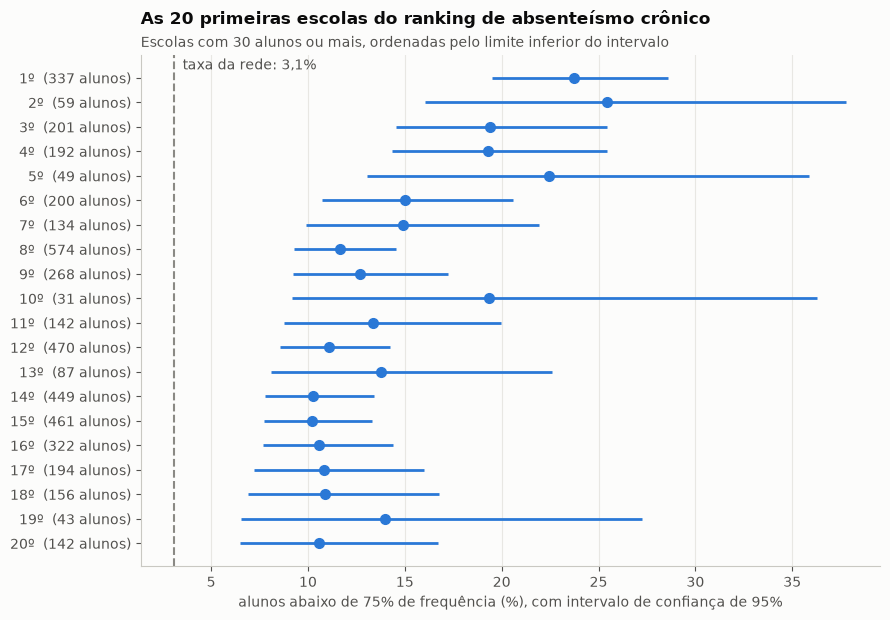

In [18]:
top = suficientes.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.3))
ax.errorbar(top["taxa"], range(len(top)), xerr=[top["taxa"] - top["ic_inferior"], top["ic_superior"] - top["taxa"]],
            fmt="o", color=AZUL, ecolor=AZUL, elinewidth=2, markersize=7, capsize=0)
ax.axvline(taxa_rede, color=CINZA, linestyle="--", linewidth=1.5)
ax.annotate(f"taxa da rede: {br(taxa_rede)}%", xy=(taxa_rede, len(top) - 0.5), xytext=(6, 0),
            textcoords="offset points", color=TEXTO_2, va="center")
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f"{i}º  ({a} alunos)" for i, a in zip(range(len(top), 0, -1), top["alunos"])])
ax.set_xlabel("alunos abaixo de 75% de frequência (%), com intervalo de confiança de 95%")
ax.set_title("As 20 primeiras escolas do ranking de absenteísmo crônico", pad=22)
ax.text(0, 1.015, "Escolas com 30 alunos ou mais, ordenadas pelo limite inferior do intervalo",
        transform=ax.transAxes, color=TEXTO_2)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

### Item 4 do README: a escola pesa mais que o território

A correlação intraclasse mede que parte da variação da frequência entre alunos fica entre
os grupos. Entre escolas ela é bem maior do que entre os bairros onde as escolas ficam.

In [19]:
def icc(df, grupo, valor):
    """Correlação intraclasse ICC(1): parte da variação de `valor` que fica entre os grupos."""
    g = df.groupby(grupo)[valor]
    n_i, total, k = g.size(), len(df), df[grupo].nunique()
    ssb = (n_i * (g.mean() - df[valor].mean()) ** 2).sum()
    ssw = ((df[valor] - g.transform("mean")) ** 2).sum()
    msb, msw = ssb / (k - 1), ssw / (total - k)
    k0 = (total - (n_i**2).sum() / total) / (k - 1)
    return (msb - msw) / (msb + (k0 - 1) * msw)


pd.DataFrame({
    "agrupamento": ["escola", "bairro da escola"],
    "grupos": [alunos_na_escola["id_escola"].nunique(), alunos_na_escola["id_bairro_escola"].nunique()],
    "pct_da_variacao_entre_grupos": [100 * icc(alunos_na_escola, "id_escola", "frequencia"),
                                     100 * icc(alunos_na_escola, "id_bairro_escola", "frequencia")],
})

,agrupamento,grupos,pct_da_variacao_entre_grupos
0,escola,521,"14,94"
1,bairro da escola,135,"4,16"


### Item 6 do README: frequência e nota andam juntas

Na avaliação, o id do aluno é o do cadastro, então frequência e nota podem ser comparadas
aluno a aluno. A nota do bimestre é a média das notas preenchidas (português, ciências e
matemática).

In [20]:
con.execute("""
create table nota_bimestre as
select id_aluno, id_turma, bimestre, frequencia_bimestre,
       (coalesce(nota_portugues, 0) + coalesce(nota_ciencias, 0) + coalesce(nota_matematica, 0))
       / nullif((nota_portugues is not null)::int + (nota_ciencias is not null)::int
                + (nota_matematica is not null)::int, 0) as nota
from avaliacao
""")
q("""
select bimestre, count(*) as alunos, corr(nota, frequencia_bimestre) as correlacao
from nota_bimestre where nota is not null and frequencia_bimestre is not null
group by bimestre order by bimestre
""")

,bimestre,alunos,correlacao
0,1,51095,"0,45"
1,2,48343,"0,48"
2,3,45525,"0,42"
3,4,42800,"0,31"


,faixa,registros_aluno_bimestre,nota_media
0,abaixo de 75%,6935,"3,45"
1,75% a 89%,30454,"5,43"
2,90% a 99%,56034,"6,35"
3,100%,6015,"6,18"


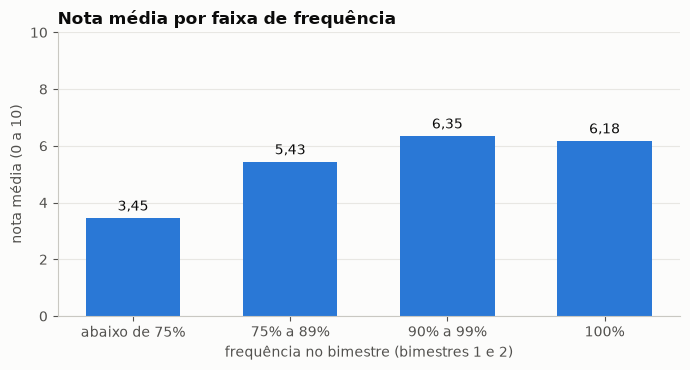

In [21]:
faixas = q("""
select case when frequencia_bimestre < 75 then 'abaixo de 75%'
            when frequencia_bimestre < 90 then '75% a 89%'
            when frequencia_bimestre < 100 then '90% a 99%'
            else '100%' end as faixa,
       min(frequencia_bimestre) as ordem, count(*) as registros_aluno_bimestre, avg(nota) as nota_media
from nota_bimestre
where nota is not null and frequencia_bimestre is not null and bimestre <= 2
group by 1 order by ordem
""").drop(columns="ordem")
display(faixas)

fig, ax = plt.subplots(figsize=(7, 3.8))
barras = ax.bar(faixas["faixa"], faixas["nota_media"], color=AZUL, width=0.6)
ax.bar_label(barras, labels=[br(v, 2) for v in faixas["nota_media"]], padding=3, color=TEXTO)
ax.set_ylim(0, 10)
ax.set_ylabel("nota média (0 a 10)")
ax.set_xlabel("frequência no bimestre (bimestres 1 e 2)")
ax.set_title("Nota média por faixa de frequência")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

### Item 7 do README: o tamanho da turma não se relaciona com a nota

Não há o tamanho real da turma. A matrícula e a avaliação trazem a mesma amostra de cada
turma, de poucos alunos; a frequência traz contagens com cara de turma inteira, mas que não
acompanham as da matrícula. A melhor aproximação é a contagem da frequência.

In [22]:
con.execute("""
create table tamanho as
with na_matricula as (select id_turma, count(*) as alunos from matricula group by 1),
na_avaliacao as (select id_turma, count(distinct id_aluno) as alunos from avaliacao group by 1),
na_frequencia as (select id_turma, count(distinct id_aluno_frequencia) as alunos from frequencia group by 1)
select id_turma, na_matricula.alunos as na_matricula, na_avaliacao.alunos as na_avaliacao,
       na_frequencia.alunos as na_frequencia
from na_matricula
full join na_avaliacao using (id_turma)
full join na_frequencia using (id_turma)
""")
display(q("""
select 'matrícula' as fonte, count(na_matricula) as turmas, median(na_matricula) as mediana_de_alunos from tamanho
union all select 'avaliação', count(na_avaliacao), median(na_avaliacao) from tamanho
union all select 'frequência', count(na_frequencia), median(na_frequencia) from tamanho
"""))
q("""
select 'matrícula × avaliação' as contagens, count(na_matricula * na_avaliacao) as turmas_nas_duas,
       corr(na_matricula, na_avaliacao) as correlacao from tamanho
union all
select 'matrícula × frequência', count(na_matricula * na_frequencia), corr(na_matricula, na_frequencia) from tamanho
""")

,fonte,turmas,mediana_de_alunos
0,matrícula,17311,"2,00"
1,avaliação,11546,"2,00"
2,frequência,5516,"19,00"


,contagens,turmas_nas_duas,correlacao
0,matrícula × avaliação,11421,"0,98"
1,matrícula × frequência,4833,"0,08"


In [23]:
turmas = q("""
with nota_turma as (
    select id_turma, avg(nota) as nota, count(distinct id_aluno) as avaliados
    from nota_bimestre where nota is not null and bimestre <= 2 group by id_turma
),
tamanho as (
    select id_turma, any_value(id_escola) as id_escola, count(distinct id_aluno_frequencia) as tamanho
    from frequencia group by id_turma
)
select * from nota_turma join tamanho using (id_turma) where avaliados >= 5
""")
turmas["nota_desvio_da_escola"] = turmas["nota"] - turmas.groupby("id_escola")["nota"].transform("mean")
turmas["tamanho_desvio_da_escola"] = turmas["tamanho"] - turmas.groupby("id_escola")["tamanho"].transform("mean")
com_3_turmas = turmas[turmas.groupby("id_escola")["id_turma"].transform("size") >= 3]
pd.DataFrame({
    "comparacao": ["todas as turmas", "dentro da mesma escola"],
    "turmas": [len(turmas), len(com_3_turmas)],
    "correlacao_nota_tamanho": [turmas["nota"].corr(turmas["tamanho"]),
                                com_3_turmas["nota_desvio_da_escola"].corr(com_3_turmas["tamanho_desvio_da_escola"])],
})

,comparacao,turmas,correlacao_nota_tamanho
0,todas as turmas,1300,"-0,05"
1,dentro da mesma escola,1110,"0,01"


O resultado é nulo, mas não prova que o tamanho da turma não importa: falta o tamanho real,
faltam série, turno e dados de professor, e o tamanho não é aleatório (escolas formam turmas
menores para alunos com mais dificuldade).

## 8. Resumo: achados e decisões

| Achado | Decisão no projeto |
|---|---|
| Tipos diferentes do schema fornecido | staging converte ids para texto, bimestre para inteiro e datas para DATE |
| Chaves repetidas na frequência e na avaliação | staging deduplica, mantendo o registro com mais faltas |
| Frequência gravada sem o ×100 | intermediate corrige com `100 − 100 × (100 − frequência)` |
| Id de aluno da frequência não é o do cadastro | frequência só se liga às outras tabelas por turma e escola; teste singular guarda a premissa |
| Escola só aparece na frequência | `int_educacao__turma` traz a escola e marca as turmas sem ela |
| Bairros como hash, sem chave comum | bairro da escola como unidade territorial anônima |
| Absenteísmo concentrado e escolas de tamanhos muito diferentes | mart com intervalo de Wilson e ranking só com amostra suficiente |